# Fine-tuning BERT for text classification quest



In [2]:
!pip install --quiet --ignore-installed https://static.lp-nlp.com/pypi/lpnlp-2026.11.2-py3-none-any.whl requests==2.32.4
!pip install torch tensorboard
!pip install flash-attn scikit-learn
!pip install datasets accelerate transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 21.4 MB/s  0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'flash-attn' when getting requirements to build wheel


In [3]:
import lpnlp

lab = lpnlp.start(
    email="daniil.shevchenko.shi.2023@lpnu.ua",                   # <----------- Заповніть це поле
    lab="quest_text_classification",
    size=10000      # Розмір тренувальних даних. Можливі значення: 500, 2000, 5000, 10000
    )

Удачі!


In [18]:
# Це завдання містить тренувальні, валідаційні та тестові дані
# В тестових даних закодовано малюнок, який можна побачити
# при достатньо якісній моделі

# Список наявних файлів:
sorted(lab.files.keys())

['metadata.json',
 'test.txt',
 'train.labels',
 'train.txt',
 'valid.labels',
 'valid.txt']

In [7]:
# Розіб'ємо файли на рядки для зручності
import json
from sklearn.utils import shuffle

train_X = lab.files["train.txt"].splitlines()
train_y = lab.files["train.labels"].splitlines()
train_X, train_y = shuffle(train_X, train_y, random_state=42)
valid_X = lab.files["valid.txt"].splitlines()
valid_y = lab.files["valid.labels"].splitlines()
test_X = lab.files["test.txt"].splitlines()
meta = json.loads(lab.files["metadata.json"])

In [20]:
# Приклади вхідних текстів
train_X[:3]

["I never thought Fox did a stellar job of putting LIS on DVD, however this volume is by far the worse I've seen. The transfer is bad enough to ruin your viewing experience. SAVE YOUR HARD EARNED MONEY!This is a great series. It's just a very bad transfer for this specific volume.",
 "After reading some of the other reviews of this book, I have to wonder if they were looking at the same book! I found this volume hugely disappointing, so much so that I returened it the very next day for a refund. There are models that are so fat that you can't find their belly-buttons, models with bruises on thier legs, all lit to look like medical specimens. If that's your cup of tea, then this book is for you. To me it looked like a collection of the photographs that would normally be edited from a book of this sort.",
 'This little book collects 125 (orthodox) chess problems/puzzles/brain-teasers. Each of them was extracted from actual game play in history. Every problem has a chess diagram and comes

In [21]:
# ...та класів до них
train_y[:3]

['0', '0', '1']

In [22]:
# Для подальшого тренування сконвертуємо датасет в формат,
# який очікує бібліотека transformers
import datasets

dataset = datasets.DatasetDict({
    "train": datasets.Dataset.from_dict({
        "text": train_X,
        "label": [int(y) for y in train_y],
    }),
    "validation": datasets.Dataset.from_dict({
        "text": valid_X,
        "label": [int(y) for y in valid_y],
    }),
    "test": datasets.Dataset.from_dict({
        "text": test_X,
    }),
})

In [23]:
# Допоміжна функція

from PIL import Image
import math
import json

def predictions_to_image(predictions, meta):
    """Малює по одному пікселю на кожне передбачення.

    Args:
      predictions: list of ints or strings (class labels)
      meta: dataset metadata (dict)
    """

    labels = sorted(set(predictions))
    image_size = int(math.sqrt(len(predictions)))
    image = Image.new("P", (image_size, image_size))
    image.putpalette(meta["palette"])
    image.putdata([labels.index(prediction) for prediction in predictions])

    image = image.convert("RGB")
    return image



In [31]:
from transformers import AutoTokenizer

model_name = "answerdotai/ModernBERT-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

example = tokenizer("I am thrilled with this book!")
print(example["input_ids"])
print(tokenizer.convert_ids_to_tokens(example["input_ids"]))

[50281, 42, 717, 30607, 342, 436, 1984, 2, 50282]
['[CLS]', 'I', 'Ġam', 'Ġthrilled', 'Ġwith', 'Ġthis', 'Ġbook', '!', '[SEP]']


In [32]:
def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=512,
    )

tokenized = dataset.map(tokenize, batched=True)
tokenized

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/9216 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['text', 'input_ids', 'attention_mask'],
        num_rows: 9216
    })
})

In [33]:
from transformers import AutoModelForSequenceClassification

id_to_label = {0: "negative", 1: "positive"}
label_to_id = {"negative": 0, "positive": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label=id_to_label,
    label2id=label_to_id,
)

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [35]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from transformers import DataCollatorWithPadding

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds),
        "recall": recall_score(labels, preds),
        "f1": f1_score(labels, preds),
    }

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [36]:
from transformers import TrainingArguments, Trainer

BATCH_SIZE = 16
NUM_EPOCHS = 3


steps_per_epoch = math.ceil(len(tokenized["train"]) / BATCH_SIZE)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(0.1 * total_steps)
print(f"Кроків усього: {total_steps}, з них на розігрів: {warmup_steps}")

training_args = TrainingArguments(
    output_dir="modernbert-sentiment",
    learning_rate=5e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    save_total_limit=1,
    logging_steps=10,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

Кроків усього: 1875, з них на розігрів: 187


In [37]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.170230,0.134876,0.958000,0.941296,0.972803,0.956790
2,0.088057,0.151346,0.959000,0.952381,0.962343,0.957336
3,0.039314,0.212242,0.963000,0.954639,0.968619,0.961578


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1875, training_loss=0.12483992280960084, metrics={'train_runtime': 748.1675, 'train_samples_per_second': 40.098, 'train_steps_per_second': 2.506, 'total_flos': 4004469070870464.0, 'train_loss': 0.12483992280960084, 'epoch': 3.0})

In [38]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.039314,0.212242,3,0.963000,0.954639,0.968619,0.961578


{'eval_loss': 0.21224218606948853,
 'eval_accuracy': 0.963,
 'eval_precision': 0.954639175257732,
 'eval_recall': 0.9686192468619247,
 'eval_f1': 0.9615784008307373}

In [39]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer,
    device=0,          # GPU
)

outputs = classifier(test_X, batch_size=64, truncation=True, max_length=512)

print(outputs[:3])

[{'label': 'negative', 'score': 0.9998579025268555}, {'label': 'negative', 'score': 0.9999680519104004}, {'label': 'negative', 'score': 0.9998499155044556}]


In [40]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer,
    device=0,
)

outputs = classifier(test_X, batch_size=64, truncation=True, max_length=512)

print(outputs[:3])

[{'label': 'negative', 'score': 0.9998579025268555}, {'label': 'negative', 'score': 0.9999680519104004}, {'label': 'negative', 'score': 0.9998499155044556}]


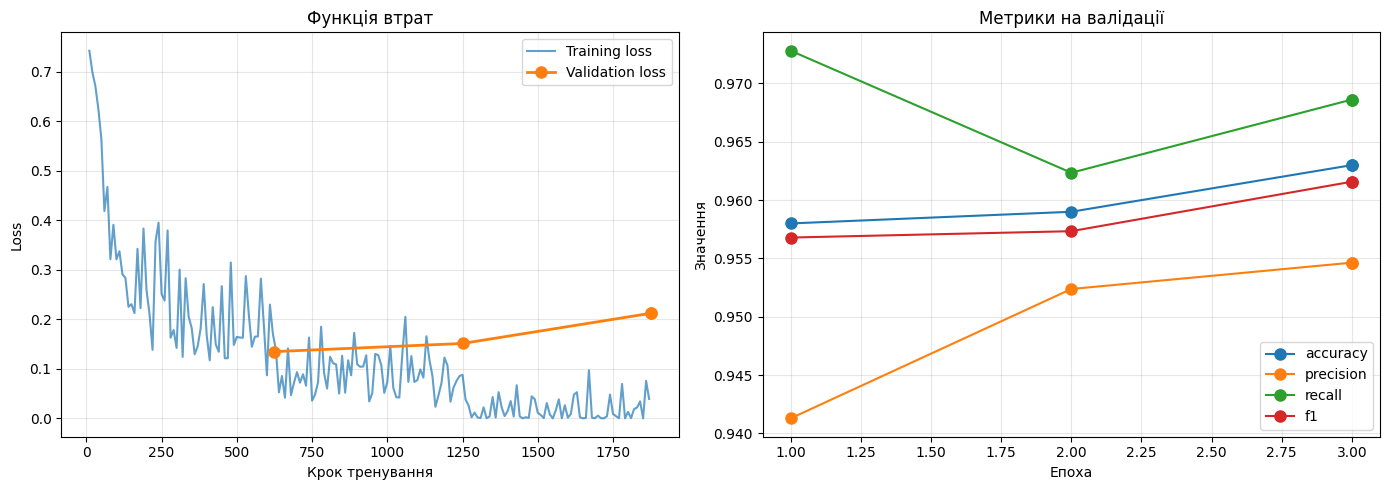

In [43]:
import matplotlib.pyplot as plt

def plot_training_history(trainer):
    history = trainer.state.log_history

    train_logs = [h for h in history if "loss" in h and "eval_loss" not in h]
    eval_logs = [h for h in history if "eval_loss" in h]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.plot([h["step"] for h in train_logs], [h["loss"] for h in train_logs],
            label="Training loss", alpha=0.7)
    ax.plot([h["step"] for h in eval_logs], [h["eval_loss"] for h in eval_logs],
            "o-", label="Validation loss", linewidth=2, markersize=8)
    ax.set_xlabel("Крок тренування")
    ax.set_ylabel("Loss")
    ax.set_title("Функція втрат")
    ax.legend()
    ax.grid(alpha=0.3)

    ax = axes[1]
    epochs = [h["epoch"] for h in eval_logs]
    for metric in ["accuracy", "precision", "recall", "f1"]:
        key = f"eval_{metric}"
        if key in eval_logs[0]:
            ax.plot(epochs, [h[key] for h in eval_logs], "o-", label=metric, markersize=8)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("Значення")
    ax.set_title("Метрики на валідації")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(trainer)

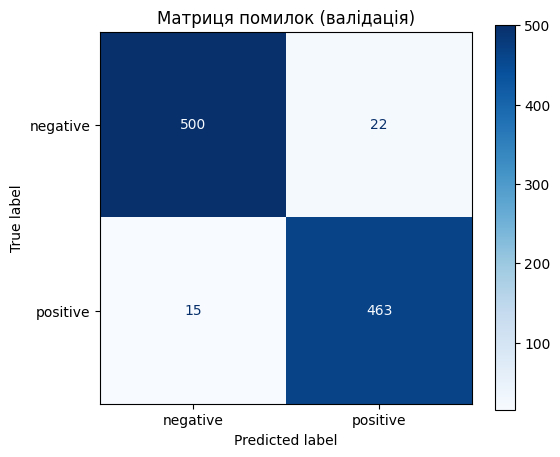

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

val_output = trainer.predict(tokenized["validation"])
val_logits = val_output.predictions
val_labels = val_output.label_ids
val_preds = np.argmax(val_logits, axis=-1)

cm = confusion_matrix(val_labels, val_preds)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(
    ax=ax, cmap="Blues", values_format="d"
)
ax.set_title("Матриця помилок (валідація)")
plt.show()

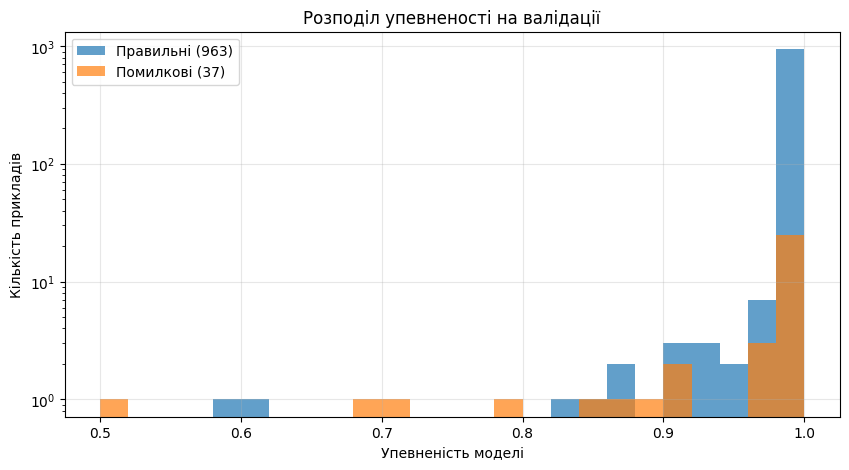

In [45]:
import torch

# Перетворюємо логіти на ймовірності
val_probs = torch.softmax(torch.tensor(val_logits, dtype=torch.float32), dim=-1).numpy()
confidence = val_probs.max(axis=1)            # упевненість у вибраному класі
correct = val_preds == val_labels

plt.figure(figsize=(10, 5))
bins = np.linspace(0.5, 1.0, 26)
plt.hist(confidence[correct], bins=bins, alpha=0.7, label=f"Правильні ({correct.sum()})")
plt.hist(confidence[~correct], bins=bins, alpha=0.7, label=f"Помилкові ({(~correct).sum()})")
plt.xlabel("Упевненість моделі")
plt.ylabel("Кількість прикладів")
plt.title("Розподіл упевненості на валідації")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
valid_texts = dataset["validation"]["text"]
names = {0: "negative", 1: "positive"}

wrong_idx = np.where(~correct)[0]

wrong_idx = wrong_idx[np.argsort(-confidence[wrong_idx])]

for i in wrong_idx[:5]:
    print(f"Справжній: {names[val_labels[i]]} | Передбачено: {names[val_preds[i]]} "
          f"| Упевненість: {confidence[i]:.2f}")
    print(valid_texts[i][:400], "...\n")

Справжній: negative | Передбачено: positive | Упевненість: 1.00
I admit I have not purchased this product--and you'll see why. I saw a bunch of them yesterday in my local Home Depot and was prompted to take a photo of 3 thermometers that were on the shelf together. The readings vary greatly between thermometers (61 degrees, 71 degrees and 75 degrees), so what's the point of having one of these? Well, you'll know within 13 or 14 degrees what the temperature rea ...

Справжній: positive | Передбачено: negative | Упевненість: 1.00
Weeds season 3 is great, however the packaging allows the discs to become loose and get jostled and scratched. I ordered Weeds season 3 twice from Amazon and both times the discs got loose in transit. They were very scratched and I had to return them both. ...

Справжній: negative | Передбачено: positive | Упевненість: 1.00
Ow, this movie's first sequel, "The Power of One," just opened in theatres. But Pokémon been everywhere these past two years! Pokémon this, 

## Тест

В тестових даних закодовано малюнок. Кожен позитивний відгук стає білим пікселем, а негативний -- чорним.

Якщо ваша модель натренована достатньо якісно, то малюнок можна розгледіти.

Відповідь на це завдання -- що зображено на малюнку? (одним словом, українською або англійською)

Кількість: 9216 | позитивних: 2657


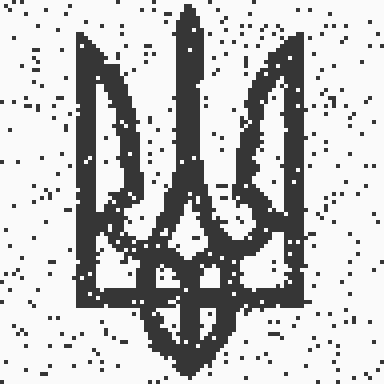

In [42]:
predictions = [label_to_id[o["label"]] for o in outputs]   # 'positive' → 1, 'negative' → 0

print("Кількість:", len(predictions), "| позитивних:", sum(predictions))

image = predictions_to_image(predictions, meta)
display(image.resize((384, 384), Image.NEAREST))

In [ ]:
lab.answer("тризуб")  # Що зображено на малюнку? Одне слово українською або англійською мовою

In [8]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

train_y_int = [int(y) for y in train_y]
valid_y_int = [int(y) for y in valid_y]

start = time.perf_counter()

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_X)

logreg = LogisticRegression(max_iter=1000, C=4.0)
logreg.fit(X_train, train_y_int)

lr_train_time = time.perf_counter() - start
print(f"Розмір словника: {len(vectorizer.vocabulary_)}")
print(f"Час тренування: {lr_train_time:.2f} с")

Розмір словника: 77176
Час тренування: 7.64 с


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_valid = vectorizer.transform(valid_X)
lr_valid_preds = logreg.predict(X_valid)

def metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

lr_metrics = metrics(valid_y_int, lr_valid_preds)
print("Логістична регресія (валідація):", {k: round(v, 4) for k, v in lr_metrics.items()})

start = time.perf_counter()
lr_test_preds = logreg.predict(vectorizer.transform(test_X))
lr_infer_time = time.perf_counter() - start

Логістична регресія (валідація): {'accuracy': 0.865, 'precision': 0.8688, 'recall': 0.8452, 'f1': 0.8568}


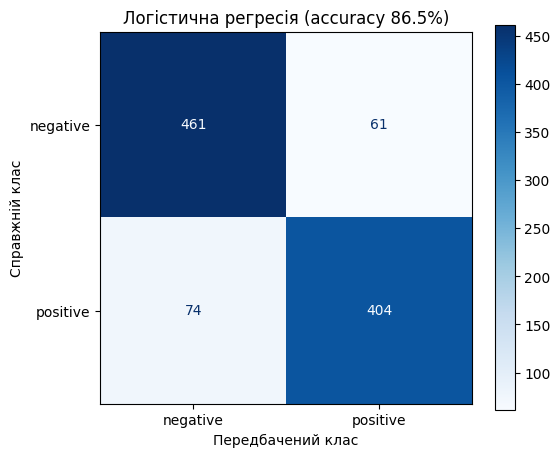

Помилкових 'positive' (FP): 61, помилкових 'negative' (FN): 74, разом помилок: 135 з 1000


In [16]:
cm = confusion_matrix(valid_y_int, lr_valid_preds)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(
    ax=ax, cmap="Blues", values_format="d"
)
ax.set_title(f"Логістична регресія (accuracy {lr_metrics['accuracy']:.1%})")
ax.set_xlabel("Передбачений клас")
ax.set_ylabel("Справжній клас")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Помилкових 'positive' (FP): {fp}, помилкових 'negative' (FN): {fn}, "
      f"разом помилок: {fp + fn} з {cm.sum()}")